# Giai đoạn 3b: Mỗi kiểu ngày đi kèm điều kiện gì? (association rules)

**Loại công việc: data mining** (khai phá luật kết hợp, *association rule mining*). Các phần kiểm tra chất lượng và kiểm định thống kê là **data analysis** hỗ trợ; phần so sánh với decision tree ở mục 9 là một mô hình **ML** đơn giản dùng làm đối chứng.

Notebook 04 đã gán cho mỗi ngày một **hình dạng** (`S1_U`, `S2_tang`, `S3_giam`, `S4_phang`) và một **bậc mức** (`thấp` ≤ 25, `TB` 25–50, `cao` > 50 µg/m³). Ở đây ta hỏi: *những tổ hợp điều kiện nào (thời tiết, điểm cháy, lịch) thường xuất hiện cùng mỗi kiểu ngày?*

**Association rule** (luật kết hợp) có dạng `{A, B} → C`: "những ngày có A và B thì thường cũng có C". Thuật ngữ:
- **Item**: một điều kiện dạng có/không, ví dụ `gió yếu`, `mưa sáng`, `S1_U`.
- **Transaction** (giao dịch): tập item của một ngày. Ở đây 1 ngày = 1 transaction.
- **Itemset**: một tập item; **frequent itemset** = itemset xuất hiện đủ thường xuyên.
- **Support** (độ hỗ trợ) của `X`: tỷ lệ ngày chứa toàn bộ `X`. Support của luật `A → C` = support(`A ∪ C`).
- **Confidence** (độ tin cậy): P(C | A) = support(A ∪ C) / support(A). "Trong những ngày có A, bao nhiêu % là C".
- **Lift**: confidence / P(C). Lift = 1: A không thay đổi khả năng gặp C; lift = 2: gặp C nhiều gấp đôi bình thường.

Thuật toán: **Apriori** và **FP-Growth** (thư viện `mlxtend`) cho **cùng** tập frequent itemset, chỉ khác tốc độ (mục 4).

Đầu vào: `data/day_clusters.csv` (2.242 ngày, sinh bởi notebook 04). Đầu ra: `data/rules_*.csv`, hình `reports/20_*.png` … `reports/27_*.png`.

**Nhắc lại:** luật kết hợp chỉ mô tả **đồng xuất hiện**, không phải nhân quả. Dữ liệu từ **một trạm** (Đại sứ quán Mỹ, Ba Đình).

In [1]:
from pathlib import Path
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import fisher_exact
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 80)

REPORT = Path("reports"); REPORT.mkdir(exist_ok=True)
OUT = Path("data"); OUT.mkdir(exist_ok=True)
S_ORDER = ["Đông", "Xuân", "Hè", "Thu"]

d = pd.read_csv(OUT / "day_clusters.csv", parse_dates=["date"]).set_index("date")
d["season"] = pd.Categorical(d["season"], S_ORDER)
print(d.shape, d.index.min().date(), "->", d.index.max().date())
d[["shape_code", "level_tier", "season", "ws_mean", "ws_eve_minus_am", "precip_sum", "blh_mean", "t_range", "rh_mean", "wind_dir_mean", "viirs_n_rrd"]].head()

(2230, 31) 2016-02-01 -> 2025-04-08


,shape_code,level_tier,season,ws_mean,ws_eve_minus_am,precip_sum,blh_mean,t_range,rh_mean,wind_dir_mean,viirs_n_rrd
date,,,,,,,,,,,
2016-02-01,S2_tang,thấp,Đông,3.5558,-0.3333,2.4,776.2500,2.5,73.9583,18.3582,0.0
2016-02-02,S2_tang,TB,Đông,2.3242,-1.5917,0.0,628.9583,2.2,55.4583,26.6612,0.0
2016-02-03,S2_tang,cao,Đông,1.3337,-0.3550,0.0,337.2917,6.3,67.8333,39.8905,0.0
2016-02-04,S3_giam,cao,Đông,2.1254,-0.5667,0.0,400.2083,3.2,74.0833,0.3393,0.0
2016-02-09,S4_phang,cao,Đông,2.1154,2.1133,0.0,417.2917,14.5,75.6250,139.4099,10.0


## 1. Kiểm tra chất lượng trước khi khai phá

Association rules đếm tần suất, nên các vấn đề cần soát là:
1. **Thiếu dữ liệu**: một biến thiếu ở một số ngày thì ngày đó sẽ không có item của biến ấy, làm support bị hạ thấp một cách lệch.
2. **Ngoại lai**: với cách rời rạc hóa theo phân vị (mục 2) thì ngoại lai chỉ rơi vào bậc cao nhất, không kéo lệch ngưỡng; nhưng cần xem có giá trị phi vật lý không.
3. **Múi giờ**: các biến "sáng/tối" (gió, mưa) được tính theo giờ địa phương ở notebook 04; nhãn ngày cũng theo giờ địa phương.
4. **Mẫu không cân bằng** giữa năm và mùa: ảnh hưởng tới kiểm tra độ vững theo năm (mục 8).

In [2]:
na = d.isna().sum(); print("Số ngày thiếu theo cột:\n", na[na > 0].to_string())
print("\nBLH thiếu theo năm:", d["blh_mean"].isna().groupby(d.index.year).sum().loc[lambda s: s > 0].to_dict())
rng = d[["ws_mean", "precip_sum", "blh_mean", "t_range", "rh_mean", "wind_dir_mean", "viirs_n_rrd"]].agg(["min", "max"]).T
print("\nKhoảng giá trị (soát giá trị phi vật lý):\n", rng.round(1).to_string())
print("\nSố ngày theo năm × mùa:\n", pd.crosstab(d.index.year, d["season"]).to_string())

Số ngày thiếu theo cột:
 blh_mean      178
blh_night     178
tet_day      2018
dlog_prev     153
dlog_next     146

BLH thiếu theo năm: {2024: 178}

Khoảng giá trị (soát giá trị phi vật lý):
                  min     max
ws_mean          0.8     5.9
precip_sum       0.0   135.3
blh_mean       122.3  1226.5
t_range          1.0    17.6
rh_mean         32.8    95.1
wind_dir_mean    0.3   359.6
viirs_n_rrd      0.0   151.0

Số ngày theo năm × mùa:
 season  Đông  Xuân   Hè  Thu
row_0                       
2016      46    46  135   57
2017      67    53  110   50
2018      53    28   93   47
2019      82    54   21   36
2020      82    56  126   56
2021      47     0   93   53
2022      61     7   26   33
2023      44    10  133   37
2024      66    60  113   57
2025      56    36    0    0


**Đọc:**
- `blh_mean` (độ cao lớp biên, *boundary layer height*) thiếu 178 ngày, toàn bộ nửa đầu 2024, do nguồn Open-Meteo (đã ghi ở Giai đoạn 1). Các ngày này sẽ **không có item BLH**; khi đọc support của luật có BLH, nhớ mẫu số thực tế nhỏ hơn ~8%.
- `tet_day` thiếu là bình thường (chỉ có giá trị gần Tết); `dlog_prev/next` thiếu khi ngày liền kề không có dữ liệu. Hai biến này không dùng làm item.
- Không có giá trị phi vật lý (gió ≥ 0, độ ẩm ≤ 100, hướng gió 0–360). Mưa và số điểm cháy lệch phải mạnh (vài ngày rất lớn): đây là lý do không chia chúng theo phân vị đều.
- Mẫu lệch: Xuân 2021–2023 và Hè 2019, 2022 rất ít ngày; 2025 chỉ có Đông–Xuân.

## 2. Rời rạc hóa (discretization): biến liên tục → item

Apriori/FP-Growth chỉ làm việc với item có/không, nên mỗi biến liên tục phải được chia thành vài khoảng. Đây là bước **quyết định nhiều nhất** tới kết quả.

| Cách | Ví dụ | Ưu | Nhược |
|---|---|---|---|
| A. Ngưỡng vật lý / quy ước | mưa ≥ 1 mm = "ngày mưa" | dễ hiểu, so được với nghiên cứu khác | không phải biến nào cũng có ngưỡng chuẩn |
| B. Phân vị toàn bộ dữ liệu | gió chia 3 phần bằng nhau trên mọi ngày | các item có support đều | **lẫn mùa**: "gió yếu" sẽ chủ yếu là ngày hè, luật tìm ra lại là mùa |
| C. Phân vị **trong từng tháng** (**chọn** cho thời tiết) | gió yếu = thuộc 1/3 thấp nhất *so với các ngày cùng tháng* | khử mùa, đúng với quyết định "so sánh trong cùng mùa" (Nhật ký 22/11) | item mang nghĩa tương đối ("yếu hơn thường lệ"), không phải giá trị tuyệt đối |
| D. Thuật toán chia khoảng có giám sát (MDLP, cây) | chọn ngưỡng tối đa hóa thông tin về nhãn | ngưỡng "tối ưu" | dễ **overfit**, ngưỡng thay đổi theo mẫu, khó giải thích |

Lựa chọn của notebook này (kết hợp A và C):
- **Gió TB, gió tối − sáng, BLH, biên độ nhiệt, độ ẩm**: 3 bậc theo phân vị **trong cùng tháng** (thấp / TB / cao so với thường lệ). Chia 3 (tercile) vì với 2.242 ngày, 3 bậc giữ mỗi item ~33% support; 5 bậc (quintile) cho item ~20% và tổ hợp 3 item sẽ quá hiếm.
- **Mưa**: ngưỡng vật lý **1 mm/ngày** (định nghĩa "ngày ẩm ướt" *wet day* trong bộ chỉ số khí hậu ETCCDI, ví dụ chỉ số R1mm/PRCPTOT: [ETCCDI](https://etccdi.pacificclimate.org/list_27_indices.shtml)). Tách thêm `mưa sáng` (0–12h) và `mưa chiều tối` (12–24h) cũng với ngưỡng 1 mm.
- **Hướng gió**: theo cung vật lý (hướng gió **thổi từ**). Hà Nội có gió mùa Đông Bắc vào mùa lạnh và gió Đông Nam vào mùa nóng; hướng Tây Nam rất hiếm trong dữ liệu (63 ngày), nên gộp thành 3 cung: `Đông Bắc` (0–90°), `Đông Nam` (90–180°), `Tây` (180–360°).
- **Điểm cháy VIIRS ở đồng bằng sông Hồng**: phân phối có rất nhiều số 0, nên dùng một item `cháy nhiều` = số điểm > 0 **và** ≥ phân vị 75% của cùng tháng.
- **Lịch**: `nghỉ Tết`, `giãn cách`, `cuối tuần`. EDA đã thấy cuối tuần không khác ngày thường, nên `cuối tuần` đóng vai **đối chứng âm** (*negative control*): nếu nó xuất hiện trong nhiều luật mạnh thì quy trình có vấn đề.
- **Mùa**: dùng theo hai cách và so sánh (mục 5 và 6): (i) đưa mùa vào như một item; (ii) khai phá riêng trong từng mùa.

In [3]:
def tercile_in_month(col, name, labels=("thấp", "TB", "cao")):
    # Thứ hạng phần trăm trong cùng tháng (gộp mọi năm). NaN giữ nguyên -> không có item.
    r = d.groupby("month")[col].rank(pct=True)
    return pd.cut(r, [0, 1/3, 2/3, 1], labels=[f"{name} {l}" for l in labels]).astype(object)

it = pd.DataFrame(index=d.index)
it["gio"]     = tercile_in_month("ws_mean", "gió", ("yếu", "TB", "mạnh"))
it["gio_tsa"] = tercile_in_month("ws_eve_minus_am", "gió tối−sáng", ("giảm", "TB", "tăng"))
it["blh"]     = tercile_in_month("blh_mean", "BLH", ("thấp", "TB", "cao"))
it["tr"]      = tercile_in_month("t_range", "biên độ nhiệt", ("nhỏ", "TB", "lớn"))
it["rh"]      = tercile_in_month("rh_mean", "ẩm", ("thấp", "TB", "cao"))

RAIN_MM = 1.0
it["mua"]      = np.where(d["precip_sum"] >= RAIN_MM, "mưa ≥1mm", "khô <1mm")
it["mua_sang"] = np.where(d["rain_0_12"] >= RAIN_MM, "mưa sáng", None)
it["mua_toi"]  = np.where(d["rain_12_24"] >= RAIN_MM, "mưa chiều tối", None)

it["huong"] = pd.cut(d["wind_dir_mean"], [0, 90, 180, 360], include_lowest=True,
                     labels=["hướng ĐBắc", "hướng ĐNam", "hướng Tây"]).astype(object)

q75 = d.groupby("month")["viirs_n_rrd"].transform(lambda s: s.quantile(0.75))
it["chay"] = np.where((d["viirs_n_rrd"] > 0) & (d["viirs_n_rrd"] >= q75), "cháy nhiều", None)

it["tet"]  = np.where(d["is_tet_holiday"], "nghỉ Tết", None)
it["ld"]   = np.where(d["lockdown"], "giãn cách", None)
it["wknd"] = np.where(d["is_weekend"], "cuối tuần", None)
it["mua_season"] = "mùa " + d["season"].astype(str)

# Item đích (target): hình dạng và bậc mức
SHAPE_NAME = {"S1_U": "S1_U", "S2_tang": "S2_tang", "S3_giam": "S3_giam", "S4_phang": "S4_phang"}
it["shape"] = d["shape_code"]
it["level"] = "mức " + d["level_tier"].astype(str)

tx = it.apply(lambda r: [x for x in r if isinstance(x, str)], axis=1)
te = TransactionEncoder()
X = pd.DataFrame(te.fit_transform(tx.tolist()), columns=te.columns_, index=d.index)

TARGETS = ["S1_U", "S2_tang", "S3_giam", "S4_phang", "mức thấp", "mức TB", "mức cao"]
SEASON_ITEMS = [f"mùa {s}" for s in S_ORDER]
COND = [c for c in X.columns if c not in TARGETS]
print("số item:", X.shape[1], "| item điều kiện:", len(COND), "| item đích:", len(TARGETS))
print("ví dụ 1 transaction:", tx.iloc[100])
X.mean().sort_values().round(3).to_frame("support").T

số item: 37 | item điều kiện: 30 | item đích: 7
ví dụ 1 transaction: ['gió yếu', 'gió tối−sáng tăng', 'BLH thấp', 'biên độ nhiệt nhỏ', 'ẩm cao', 'mưa ≥1mm', 'mưa sáng', 'mưa chiều tối', 'hướng ĐNam', 'mùa Hè', 'S4_phang', 'mức TB']


,nghỉ Tết,giãn cách,hướng Tây,mùa Xuân,S2_tang,S3_giam,mùa Thu,mức thấp,S1_U,mùa Đông,...,ẩm cao,gió tối−sáng tăng,biên độ nhiệt lớn,hướng ĐBắc,mùa Hè,S4_phang,mức TB,mưa ≥1mm,hướng ĐNam,khô <1mm
support,0.023,0.029,0.139,0.157,0.186,0.189,0.191,0.229,0.24,0.271,...,0.336,0.336,0.338,0.356,0.381,0.386,0.457,0.462,0.505,0.538


**Kiểm tra rời rạc hóa:** các item theo phân vị trong tháng đều có support ~0,33 (đúng thiết kế); `BLH` thấp hơn một chút vì 178 ngày thiếu. Kiểm tra nhanh rằng cách C thật sự khử được mùa: tỷ lệ "gió yếu" theo mùa phải gần như nhau, trong khi nếu chia theo phân vị toàn bộ (cách B) thì sẽ lệch hẳn.

Tỷ lệ ngày 'gió yếu' theo mùa:
         B: phân vị toàn bộ  C: phân vị trong tháng
season                                            
Đông                  0.30                    0.33
Xuân                  0.19                    0.33
Hè                    0.40                    0.33
Thu                   0.35                    0.33


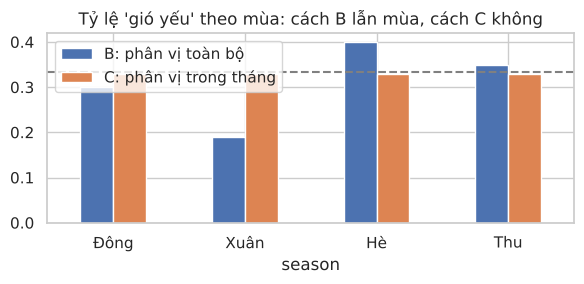

In [4]:
gB = pd.qcut(d["ws_mean"], 3, labels=["yếu", "TB", "mạnh"])
cmp = pd.DataFrame({
    "B: phân vị toàn bộ": (gB == "yếu").groupby(d["season"], observed=True).mean(),
    "C: phân vị trong tháng": X["gió yếu"].groupby(d["season"], observed=True).mean(),
}).round(2)
print("Tỷ lệ ngày 'gió yếu' theo mùa:\n", cmp.to_string())
fig, ax = plt.subplots(figsize=(6, 3)); cmp.plot(kind="bar", ax=ax, rot=0); ax.axhline(1/3, ls="--", c="grey")
ax.set_title("Tỷ lệ 'gió yếu' theo mùa: cách B lẫn mùa, cách C không"); plt.tight_layout(); plt.savefig(REPORT / "20_discretize_check.png"); plt.show()

## 3. Tỷ lệ nền (base rate) của các item đích

Lift so sánh với tỷ lệ nền, nên cần biết trước: kiểu nào phổ biến, kiểu nào hiếm, và tỷ lệ này đổi theo mùa ra sao. Nếu tỷ lệ nền đổi mạnh theo mùa thì một luật toàn cục như `{mùa Thu} → mức cao` sẽ "đúng" nhưng không mới.

          toàn bộ   Đông   Xuân     Hè    Thu
S1_U        0.240  0.215  0.117  0.224  0.408
S2_tang     0.186  0.240  0.169  0.171  0.153
S3_giam     0.189  0.195  0.149  0.193  0.204
S4_phang    0.386  0.349  0.566  0.413  0.235
mức thấp    0.229  0.096  0.103  0.412  0.155
mức TB      0.457  0.361  0.580  0.501  0.406
mức cao     0.314  0.543  0.317  0.087  0.439


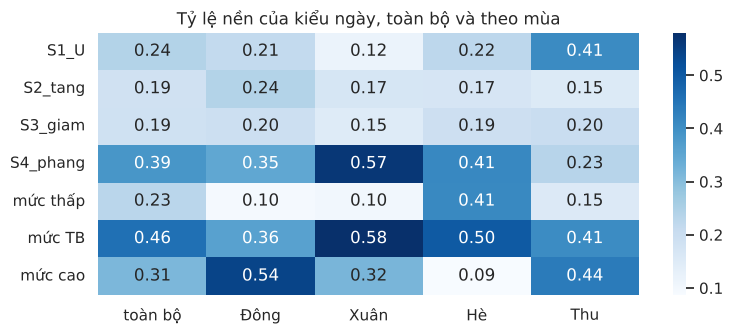

In [5]:
base = X[TARGETS].mean().rename("toàn bộ")
by_season = X[TARGETS].groupby(d["season"], observed=True).mean().T
base_tab = pd.concat([base, by_season], axis=1).round(3)
print(base_tab.to_string())
fig, ax = plt.subplots(figsize=(8, 3.5)); sns.heatmap(base_tab, annot=True, fmt=".2f", cmap="Blues", ax=ax)
ax.set_title("Tỷ lệ nền của kiểu ngày, toàn bộ và theo mùa"); plt.tight_layout(); plt.savefig(REPORT / "21_base_rates.png"); plt.show()

## 4. Chọn `min_support`, so sánh Apriori và FP-Growth

**Apriori** sinh itemset theo từng độ dài k và cắt tỉa nhờ tính chất *mọi tập con của một tập phổ biến cũng phổ biến*; phải quét dữ liệu nhiều lần. **FP-Growth** nén dữ liệu vào cây FP-tree rồi khai phá đệ quy, không sinh ứng viên; thường nhanh hơn nhiều khi `min_support` thấp. Hai thuật toán **cho cùng kết quả**; khác biệt chỉ là tốc độ và bộ nhớ. (Lựa chọn khác: **Eclat** dùng danh sách ngày theo chiều dọc, cũng cho cùng kết quả; `mlxtend` có `hmine` tương tự.)

**Cách chọn `min_support`:** nghĩ theo **số ngày tuyệt đối**. Một luật dựa trên dưới ~20 ngày (≈ 1% của 2.242) dễ là trùng hợp, và khi chia theo năm (mục 8) sẽ chỉ còn 2–3 ngày mỗi năm. Ở đây chọn **min_support = 0,02** (≈ 45 ngày) cho khai phá toàn bộ, và **≥ 20 ngày** khi khai phá trong từng mùa (mẫu nhỏ hơn). Giới hạn `max_len = 4` (tối đa 3 điều kiện + 1 kiểu ngày) để luật còn đọc được.

 min_support  ≈ số ngày  số itemset  giây FP-Growth
        0.01         22       18035            0.74
        0.02         45        9104            0.31
        0.03         67        5150            0.35
        0.05        112        2051            0.14
        0.08        178         768            0.09
        0.10        223         437            0.17



min_support=0.02: Apriori 9104 itemset, 0.17s | FP-Growth 9104 itemset, 0.44s | cùng kết quả: True


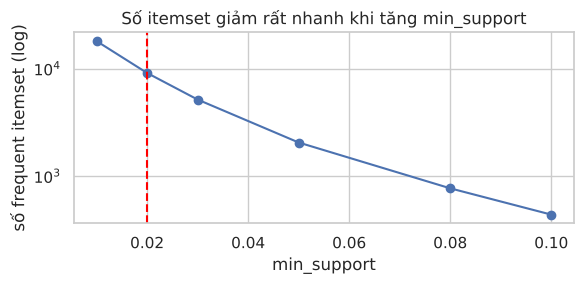

In [6]:
grid = []
for ms in [0.01, 0.02, 0.03, 0.05, 0.08, 0.10]:
    t0 = time.perf_counter(); fi = fpgrowth(X, min_support=ms, use_colnames=True, max_len=4); t_fp = time.perf_counter() - t0
    grid.append({"min_support": ms, "≈ số ngày": round(ms * len(X)), "số itemset": len(fi), "giây FP-Growth": round(t_fp, 2)})
grid = pd.DataFrame(grid); print(grid.to_string(index=False))

MIN_SUP = 0.02
t0 = time.perf_counter(); fi_ap = apriori(X, min_support=MIN_SUP, use_colnames=True, max_len=4); t_ap = time.perf_counter() - t0
t0 = time.perf_counter(); fi = fpgrowth(X, min_support=MIN_SUP, use_colnames=True, max_len=4); t_fp = time.perf_counter() - t0
same = set(map(frozenset, fi_ap["itemsets"])) == set(map(frozenset, fi["itemsets"]))
print(f"\nmin_support={MIN_SUP}: Apriori {len(fi_ap)} itemset, {t_ap:.2f}s | FP-Growth {len(fi)} itemset, {t_fp:.2f}s | cùng kết quả: {same}")

fig, ax = plt.subplots(figsize=(6, 3)); ax.plot(grid["min_support"], grid["số itemset"], marker="o"); ax.set_yscale("log")
ax.axvline(MIN_SUP, ls="--", c="red"); ax.set_xlabel("min_support"); ax.set_ylabel("số frequent itemset (log)")
ax.set_title("Số itemset giảm rất nhanh khi tăng min_support"); plt.tight_layout(); plt.savefig(REPORT / "22_min_support.png"); plt.show()

## 5. Sinh luật và lọc: chỉ giữ luật `điều kiện → kiểu ngày`

`association_rules` sinh **mọi** luật từ các itemset, kể cả luật vô nghĩa với câu hỏi như `{S1_U} → gió yếu` hay `{gió yếu} → BLH thấp`. Ta lọc:
1. **Vế phải (consequent)** đúng **một** item đích (một hình dạng hoặc một bậc mức).
2. **Vế trái (antecedent)** chỉ gồm item điều kiện (không chứa item đích khác).

**Chọn `min_confidence`:** tỷ lệ nền rất khác nhau (`S4_phang` 39%, `S2_tang` 18%). Một ngưỡng confidence cố định, ví dụ 0,5, sẽ gần như loại hết luật về `S2_tang` dù luật đó tăng gấp 2,5 lần khả năng. Vì vậy dùng **lift** làm tiêu chí chính và đặt confidence tương đối:
- `lift ≥ 1,3` (tăng ít nhất 30% so với nền);
- `confidence ≥ 1,3 × tỷ lệ nền` (tương đương), không đặt ngưỡng tuyệt đối.

Các thước đo khác có trong `mlxtend`: **leverage** = support(A∪C) − support(A)·support(C) (chênh lệch tuyệt đối, ưu tiên luật phổ biến); **conviction** = (1 − P(C)) / (1 − confidence) (nhạy với confidence gần 1); **Zhang's metric** (−1 đến 1, đối xứng). Lift dễ diễn giải nhất nên dùng làm chính; leverage được in kèm để thấy "bao nhiêu ngày thật sự".

Hai bước bổ sung để tránh bị ngập luật và luật ngẫu nhiên:
3. **Luật có ích (productive rule, theo Webb 2007):** luật `{A, B} → C` chỉ được giữ nếu confidence của nó **cao hơn** mọi luật con (`{A} → C`, `{B} → C`, và tỷ lệ nền) ít nhất 0,05. Nếu không, thêm B chẳng bổ sung gì, luật chỉ là bản sao của `{A} → C`.
4. **Kiểm định Fisher** (*Fisher's exact test*, kiểm định chính xác cho bảng 2×2), một phía, cho **từng item** của vế trái: trong các ngày đã thỏa phần còn lại của vế trái, có thêm item này thì tỷ lệ kiểu ngày có tăng thật không? Luật chỉ được giữ nếu **mọi** item đều qua (lấy p lớn nhất). Sau đó hiệu chỉnh **Benjamini–Hochberg** (kiểm soát tỷ lệ phát hiện sai, *FDR*) vì ta thử hàng trăm luật; giữ luật có q < 0,05. Bước này chặn các luật kiểu `{gió yếu, cuối tuần} → mức cao`, nơi `cuối tuần` chỉ "đi nhờ" một điều kiện mạnh. Đây là phần **analysis** chống "khai phá ra nhiễu".

In [7]:
def mine_rules(Xs, min_count=None, min_sup=None, max_len=4, lift_min=1.3, improve=0.05, alpha=0.05, conds=None):
    n = len(Xs)
    min_sup = min_sup if min_sup is not None else min_count / n
    conds = conds if conds is not None else [c for c in Xs.columns if c not in TARGETS]
    cols = [c for c in conds + TARGETS if c in Xs.columns and Xs[c].sum() > 0]
    Xs = Xs[cols]
    fi = fpgrowth(Xs, min_support=min_sup, use_colnames=True, max_len=max_len)
    ru = association_rules(fi, metric="lift", min_threshold=1.0, num_itemsets=n)
    tset = set(TARGETS)
    ru = ru[ru["consequents"].apply(lambda s: len(s) == 1 and next(iter(s)) in tset)
            & ru["antecedents"].apply(lambda s: not (s & tset))].copy()
    ru["target"] = ru["consequents"].apply(lambda s: next(iter(s)))
    ru["base"] = ru["target"].map(Xs.mean())
    ru = ru[(ru["lift"] >= lift_min)].copy()
    # -- luật có ích: confidence phải vượt mọi luật con ít nhất `improve`
    def conf(items, t):
        m = Xs[list(items)].all(axis=1) if items else pd.Series(True, index=Xs.index)
        return Xs.loc[m, t].mean()
    def productive(row):
        A, t = sorted(row["antecedents"]), row["target"]
        best_sub = row["base"]
        for k in range(1, len(A)):
            from itertools import combinations
            for sub in combinations(A, k):
                best_sub = max(best_sub, conf(sub, t))
        return row["confidence"] - best_sub >= improve
    ru = ru[ru.apply(productive, axis=1)].copy()
    # -- Kiểm định Fisher một phía cho MỖI item của vế trái: trong các ngày thỏa phần còn lại của vế trái,
    #    thêm item này có làm tăng tỷ lệ đích không? Lấy p lớn nhất (item yếu nhất quyết định).
    #    Với luật 1 điều kiện, đây là Fisher thông thường (có A hay không × có C hay không).
    def pval(row):
        A, t = list(row["antecedents"]), row["target"]
        ps = []
        for a in A:
            rest = [x for x in A if x != a]
            m = Xs[rest].all(axis=1) if rest else pd.Series(True, index=Xs.index)
            ia, c = Xs.loc[m, a], Xs.loc[m, t]
            tab = [[int((ia & c).sum()), int((ia & ~c).sum())], [int((~ia & c).sum()), int((~ia & ~c).sum())]]
            ps.append(fisher_exact(tab, alternative="greater")[1])
        return max(ps)
    ru["p"] = ru.apply(pval, axis=1)
    # Benjamini-Hochberg trên toàn bộ luật ứng viên
    m = len(ru)
    if m:
        p_sorted = ru["p"].sort_values()
        q = (p_sorted * m / np.arange(1, m + 1))[::-1].cummin()[::-1].clip(upper=1)
        ru["q"] = q.reindex(ru.index)
    else:
        ru["q"] = []
    ru = ru[ru["q"] < alpha].copy()
    ru["n_days"] = (ru["support"] * n).round().astype(int)
    ru["luật"] = ru["antecedents"].apply(lambda s: " + ".join(sorted(s))) + "  →  " + ru["target"]
    return ru.sort_values(["target", "lift"], ascending=[True, False])

SHOW = ["luật", "n_days", "support", "confidence", "base", "lift", "leverage", "q"]
t0 = time.perf_counter()
rules_all = mine_rules(X, min_sup=MIN_SUP)
print(f"luật toàn bộ (có mùa là item): {len(rules_all)}  ({time.perf_counter()-t0:.1f}s)")
print(rules_all["target"].value_counts().reindex(TARGETS).fillna(0).astype(int).to_string())

luật toàn bộ (có mùa là item): 353  (10.3s)
target
S1_U         75
S2_tang      28
S3_giam       9
S4_phang     28
mức thấp     88
mức TB       19
mức cao     106


In [8]:
def top(ru, k=5):
    return ru.groupby("target", group_keys=False).apply(lambda g: g.nlargest(k, "lift"))[SHOW].round(3)
top(rules_all, 4)

,luật,n_days,support,confidence,base,lift,leverage,q
73761,biên độ nhiệt lớn + mùa Thu + ẩm thấp → S1_U,47,0.021,0.825,0.240,3.437,0.015,0.001
74202,cháy nhiều + mùa Thu + ẩm thấp → S1_U,51,0.023,0.810,0.240,3.374,0.016,0.001
74132,cháy nhiều + hướng ĐBắc + mùa Thu → S1_U,57,0.026,0.781,0.240,3.255,0.018,0.000
60576,cháy nhiều + hướng Tây + ẩm thấp → S1_U,45,0.020,0.738,0.240,3.075,0.014,0.044
21456,BLH cao + gió tối−sáng giảm + mùa Đông → S2_tang,54,0.024,0.540,0.186,2.909,0.016,0.007
21442,BLH cao + mùa Đông + ẩm thấp → S2_tang,50,0.022,0.500,0.186,2.693,0.014,0.000
21414,gió tối−sáng giảm + mùa Đông + ẩm thấp → S2_tang,59,0.026,0.496,0.186,2.671,0.017,0.047
21428,BLH cao + hướng ĐBắc + mùa Đông → S2_tang,55,0.025,0.474,0.186,2.554,0.015,0.000
44883,biên độ nhiệt lớn + gió tối−sáng tăng + mùa Đông → S3_giam,47,0.021,0.431,0.189,2.284,0.012,0.008
47190,hướng ĐNam + mùa Thu → S3_giam,47,0.021,0.373,0.189,1.976,0.010,0.000


**Đọc (mùa là một item):** rất nhiều luật mạnh chứa `mùa …` ở vế trái. Điều đó đúng nhưng không mới: notebook 03–04 đã cho thấy mùa quyết định phần lớn mức PM2.5 và tỷ lệ các hình dạng. Lift ở đây so với tỷ lệ nền **toàn năm**, nên một phần lift chỉ là "mùa Đông bẩn hơn mùa Hè". Để biết *trong cùng một mùa* điều kiện nào còn đi kèm, ta khai phá riêng từng mùa.

Kiểm tra đối chứng âm: `cuối tuần` có xuất hiện trong luật nào không?

In [9]:
neg = rules_all[rules_all["antecedents"].apply(lambda s: "cuối tuần" in s)]
print("số luật chứa 'cuối tuần':", len(neg), "/", len(rules_all))
if len(neg): print(neg[SHOW].round(3).head(10).to_string())

số luật chứa 'cuối tuần': 4 / 353
                                                       luật  n_days  support  confidence   base   lift  leverage      q
57187  BLH thấp + cuối tuần + gió tối−sáng tăng  →  mức cao      45    0.020       0.600  0.314  1.911     0.010  0.044
55632                       cuối tuần + gió yếu  →  mức cao     119    0.053       0.569  0.314  1.814     0.024  0.034
16850             BLH cao + cuối tuần + mùa Hè  →  mức thấp      50    0.022       0.575  0.229  2.513     0.013  0.047
16688                      BLH cao + cuối tuần  →  mức thấp      80    0.036       0.383  0.229  1.674     0.014  0.038


## 6. Khai phá trong từng mùa (cách chính)

Trong mỗi mùa, bỏ item mùa, chạy lại FP-Growth với `min_support` = 20 ngày của mùa đó. Lift lúc này được tính so với **tỷ lệ nền của mùa**, nên trả lời đúng câu hỏi "cùng là mùa Đông, những ngày có điều kiện X khác gì".

Lựa chọn khác:
- **Giữ mùa làm item và chỉ xét luật có chứa mùa**: lift vẫn so với nền toàn năm, nên lẫn hiệu ứng mùa.
- **Rời rạc hóa theo tháng (đã làm) + không tách mùa**: đã khử mùa ở vế trái nhưng vế phải (kiểu ngày) vẫn đổi theo mùa.
- Tách theo **tháng**: quá ít ngày (≈ 190 ngày/tháng) cho luật 3 điều kiện.

In [10]:
MIN_DAYS = 20
season_rules = []
for s in S_ORDER:
    Xs = X[d["season"] == s].drop(columns=SEASON_ITEMS)
    ru = mine_rules(Xs, min_count=MIN_DAYS)
    ru.insert(0, "season", s)
    season_rules.append(ru)
    print(f"{s}: {len(Xs)} ngày, min_support={MIN_DAYS/len(Xs):.3f} -> {len(ru)} luật")
rules_season = pd.concat(season_rules, ignore_index=True)
print(pd.crosstab(rules_season["target"], rules_season["season"]).reindex(index=TARGETS, columns=S_ORDER).fillna(0).astype(int).to_string())

Đông: 604 ngày, min_support=0.033 -> 108 luật


Xuân: 350 ngày, min_support=0.057 -> 53 luật


Hè: 850 ngày, min_support=0.024 -> 64 luật


Thu: 426 ngày, min_support=0.047 -> 76 luật
season    Đông  Xuân  Hè  Thu
target                       
S1_U        14     5  18   19
S2_tang     19     9   2    3
S3_giam      8     1   2    5
S4_phang     8     6   4    8
mức thấp    19     4  27   14
mức TB      15     6   1    7
mức cao     25    22  10   20


In [11]:
for s in S_ORDER:
    g = rules_season[rules_season["season"] == s]
    print(f"\n===== {s} =====")
    print(g.groupby("target", group_keys=False).apply(lambda x: x.nlargest(3, "lift"))[SHOW].round(3).to_string(index=False))


===== Đông =====
                                                      luật  n_days  support  confidence  base  lift  leverage     q
                     cháy nhiều + gió tối−sáng TB  →  S1_U      25    0.041       0.532 0.215 2.471     0.025 0.001
                        gió tối−sáng TB + ẩm thấp  →  S1_U      26    0.043       0.510 0.215 2.369     0.025 0.021
                   BLH TB + hướng ĐBắc + khô <1mm  →  S1_U      28    0.046       0.500 0.215 2.323     0.026 0.010
          BLH cao + biên độ nhiệt TB + ẩm thấp  →  S2_tang      20    0.033       0.741 0.240 3.086     0.022 0.011
biên độ nhiệt TB + gió tối−sáng giảm + ẩm thấp  →  S2_tang      23    0.038       0.719 0.240 2.994     0.025 0.010
         BLH cao + gió tối−sáng giảm + ẩm thấp  →  S2_tang      47    0.078       0.603 0.240 2.510     0.047 0.039
BLH TB + biên độ nhiệt lớn + gió tối−sáng tăng  →  S3_giam      26    0.043       0.565 0.195 2.893     0.028 0.033
         biên độ nhiệt lớn + gió tối−sáng tăng  →  S3_

Để dễ nhìn hơn: với **từng item điều kiện đơn lẻ**, lift của nó với từng kiểu ngày trong từng mùa. Đây là các luật 1 điều kiện (chưa lọc), vẽ thành bản đồ nhiệt; ô đỏ = điều kiện đó đi kèm kiểu ngày nhiều hơn bình thường của mùa, ô xanh = ít hơn.

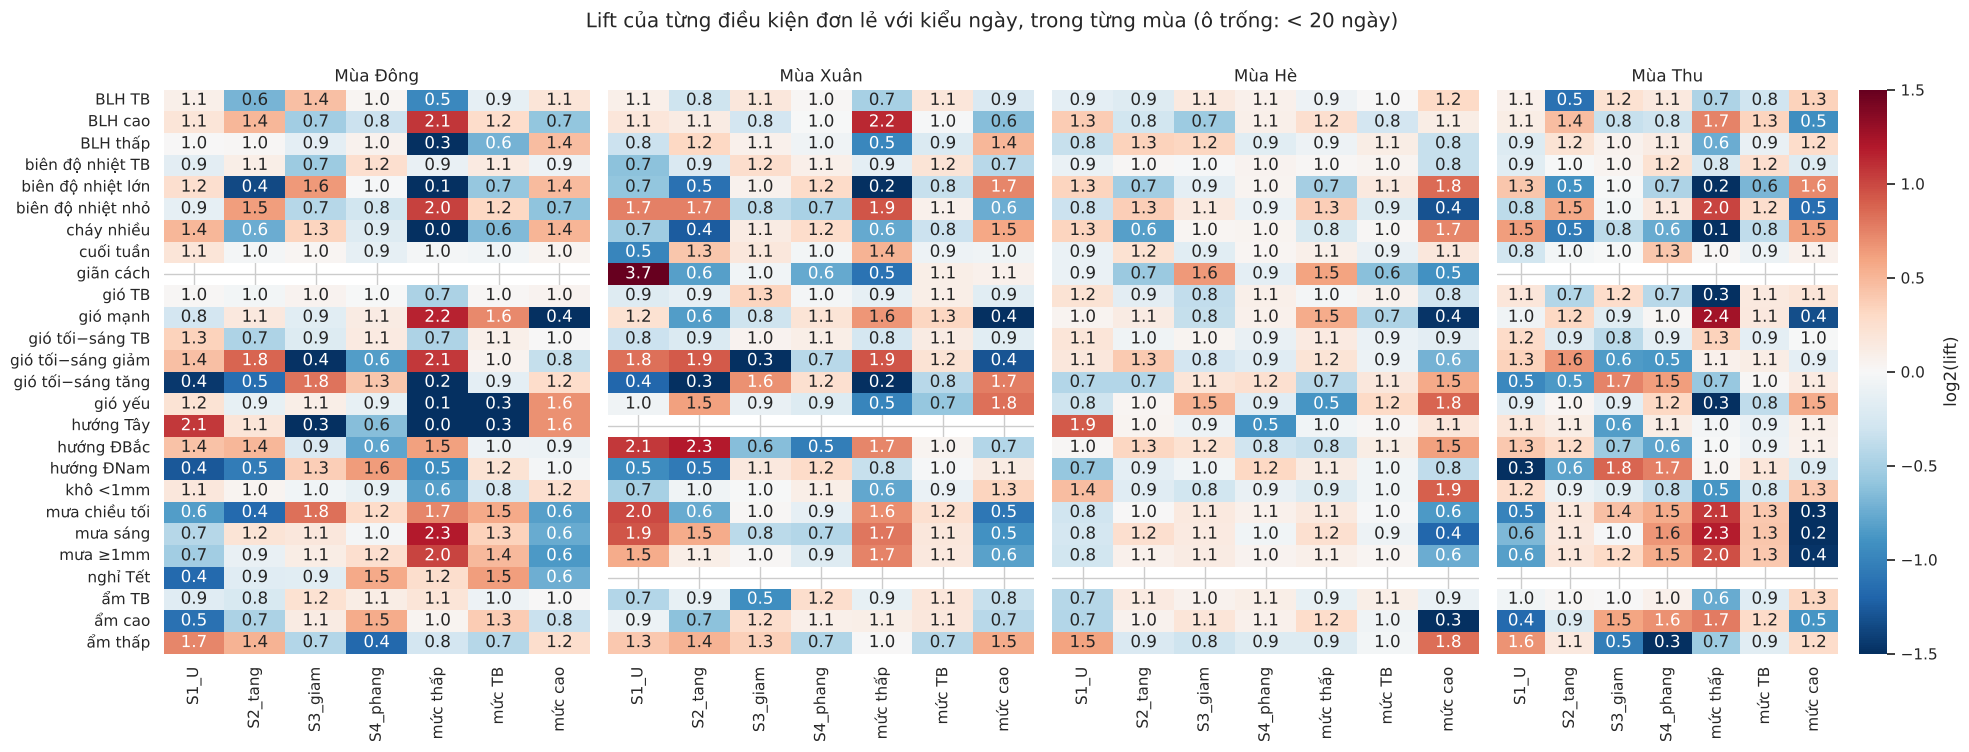

In [12]:
COND1 = [c for c in COND if c not in SEASON_ITEMS]
rows = []
for s in S_ORDER:
    Xs = X[d["season"] == s]
    for a in COND1:
        m = Xs[a]
        if m.sum() < MIN_DAYS: continue
        for t in TARGETS:
            p = Xs[t].mean()
            rows.append({"season": s, "điều kiện": a, "target": t, "lift": Xs.loc[m, t].mean() / p if p > 0 else np.nan, "n": int(m.sum())})
L1 = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 4, figsize=(20, 7.5), sharey=True)
order_c = sorted(COND1)
for ax, s in zip(axes, S_ORDER):
    piv = L1[L1["season"] == s].pivot(index="điều kiện", columns="target", values="lift").reindex(index=order_c, columns=TARGETS)
    sns.heatmap(np.log2(piv.clip(lower=0.25)), cmap="RdBu_r", center=0, vmin=-1.5, vmax=1.5, annot=piv.round(1), fmt="", ax=ax, cbar=(s == "Thu"),
                cbar_kws={"label": "log2(lift)"})
    ax.set_title(f"Mùa {s}"); ax.set_xlabel(""); ax.set_ylabel("")
plt.suptitle("Lift của từng điều kiện đơn lẻ với kiểu ngày, trong từng mùa (ô trống: < 20 ngày)", y=1.0)
plt.tight_layout(); plt.savefig(REPORT / "23_lift_heatmap.png", bbox_inches="tight"); plt.show()

## 7. Hình dung luật: support × confidence × lift

Mỗi điểm là một luật đã qua lọc (trong từng mùa). Trục x: số ngày luật bao phủ; trục y: confidence chia tỷ lệ nền (= lift). Luật tốt nằm **phía trên bên phải**: vừa mạnh vừa không quá hiếm.

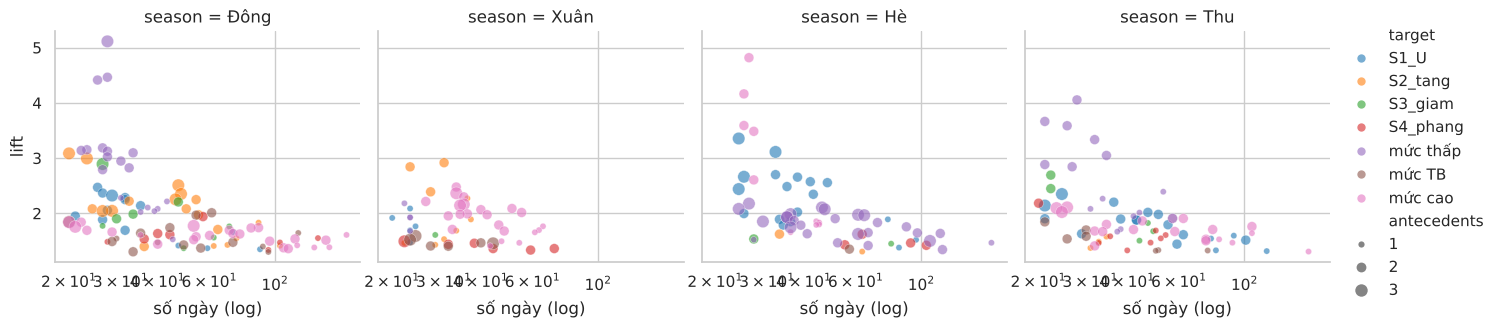

In [13]:
g = sns.relplot(data=rules_season, x="n_days", y="lift", hue="target", hue_order=TARGETS, col="season", col_order=S_ORDER,
                size=rules_season["antecedents"].apply(len), sizes=(20, 80), alpha=0.6, height=3.4, aspect=1.0, palette="tab10")
g.set(xscale="log"); g.set_axis_labels("số ngày (log)", "lift")
plt.savefig(REPORT / "24_rules_scatter.png", bbox_inches="tight"); plt.show()

## 8. Độ vững (robustness): luật có còn khi chia theo năm không?

Một luật tìm được trên toàn bộ dữ liệu có thể chỉ đến từ 1–2 năm đặc biệt (ví dụ một đợt cháy lớn). Hai cách kiểm tra:

1. **Theo từng năm**: tính lại lift của luật trong mỗi năm (chỉ những năm có ≥ 5 ngày thỏa vế trái trong mùa đó). Đếm tỷ lệ năm có lift > 1.
2. **Chia trước/sau (temporal holdout)**: khai phá trên **2016–2020**, rồi đo luật trên **2021–2025** (dữ liệu chưa thấy). Luật vững phải vẫn có lift > 1 ở giai đoạn sau. Đây là cách dùng tư duy train/test của ML để kiểm tra kết quả mining.

Tiêu chí "vững" (lựa chọn của notebook, có thể đổi): lift > 1 ở **≥ 75% số năm đánh giá được** (cần ít nhất 4 năm) **và** lift > 1,1 ở giai đoạn 2021–2025.

Holdout: số luật tìm trên 2016–2020: 161 | đo được ở 2021–2025 (>=5 ngày): 159
  trong đó lift 2021–25 > 1: 93% | > 1,1: 89% | tương quan lift hai giai đoạn (Spearman): 0.43



Luật vững / tổng theo mùa:
         sum  count
season            
Đông     92    108
Xuân     46     53
Hè       59     64
Thu      60     76


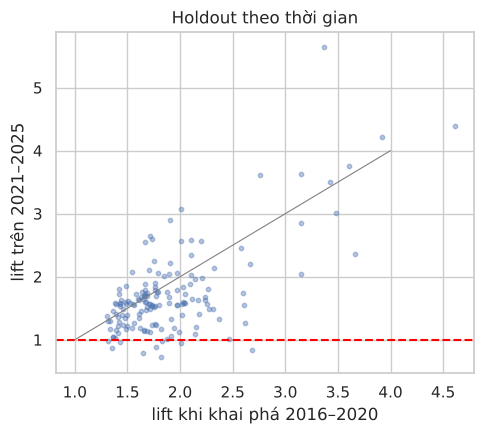

In [14]:
years = sorted(d.index.year.unique())

def rule_lift(Xs, A, t, min_a=5):
    a = Xs[list(A)].all(axis=1)
    if a.sum() < min_a or Xs[t].mean() == 0: return np.nan, int(a.sum())
    return Xs.loc[a, t].mean() / Xs[t].mean(), int(a.sum())

def robustness(ru):
    out = []
    for _, r in ru.iterrows():
        Xs = X[d["season"] == r["season"]]
        yr = d.index.year[d["season"] == r["season"]]
        lifts = {}
        for y in years:
            l, na_ = rule_lift(Xs[yr == y], r["antecedents"], r["target"])
            if not np.isnan(l): lifts[y] = l
        lv = np.array(list(lifts.values()))
        out.append({"n_years": len(lv), "share_years_lift>1": (lv > 1).mean() if len(lv) else np.nan,
                    "min_lift_year": lv.min() if len(lv) else np.nan, "median_lift_year": np.median(lv) if len(lv) else np.nan,
                    "lift_by_year": lifts})
    return pd.DataFrame(out, index=ru.index)

rob = robustness(rules_season)
rules_season = rules_season.join(rob)

# Holdout theo thời gian
early, late = d.index.year <= 2020, d.index.year >= 2021
ho = []
for s in S_ORDER:
    m_s = (d["season"] == s).values
    ru_e = mine_rules(X[m_s & early].drop(columns=SEASON_ITEMS), min_count=MIN_DAYS * 0.6)
    for _, r in ru_e.iterrows():
        l, na_ = rule_lift(X[m_s & late], r["antecedents"], r["target"])
        ho.append({"season": s, "luật": r["luật"], "lift_2016_20": r["lift"], "lift_2021_25": l, "n_2021_25": na_})
ho = pd.DataFrame(ho)
print("Holdout: số luật tìm trên 2016–2020:", len(ho), "| đo được ở 2021–2025 (>=5 ngày):", ho["lift_2021_25"].notna().sum())
print("  trong đó lift 2021–25 > 1:", f"{(ho['lift_2021_25'] > 1).mean():.0%}", "| > 1,1:", f"{(ho['lift_2021_25'] > 1.1).mean():.0%}",
      "| tương quan lift hai giai đoạn (Spearman):", round(ho[["lift_2016_20", "lift_2021_25"]].corr("spearman").iloc[0, 1], 2))
rules_season = rules_season.merge(ho[["season", "luật", "lift_2021_25"]], on=["season", "luật"], how="left")
# với luật không tìm thấy ở giai đoạn đầu, vẫn đo lift giai đoạn sau trực tiếp
miss = rules_season["lift_2021_25"].isna()
rules_season.loc[miss, "lift_2021_25"] = [rule_lift(X[(d["season"] == r["season"]).values & late], r["antecedents"], r["target"])[0]
                                          for _, r in rules_season[miss].iterrows()]
rules_season["vững"] = ((rules_season["n_years"] >= 4) & (rules_season["share_years_lift>1"] >= 0.75)
                        & (rules_season["lift_2021_25"] > 1.1))
print("\nLuật vững / tổng theo mùa:\n", rules_season.groupby("season", observed=True)["vững"].agg(["sum", "count"]).reindex(S_ORDER).to_string())

fig, ax = plt.subplots(figsize=(5, 4.5))
ax.scatter(ho["lift_2016_20"], ho["lift_2021_25"], s=10, alpha=0.4)
ax.axhline(1, c="red", ls="--"); ax.plot([1, 4], [1, 4], c="grey", lw=0.8)
ax.set_xlabel("lift khi khai phá 2016–2020"); ax.set_ylabel("lift trên 2021–2025"); ax.set_title("Holdout theo thời gian")
plt.tight_layout(); plt.savefig(REPORT / "25_holdout.png"); plt.show()

**Đọc holdout:** điểm nằm dưới đường đỏ là luật "mất" ở giai đoạn sau. Lift ở giai đoạn sau thường **thấp hơn** giai đoạn khai phá (điểm nằm dưới đường chéo): đây là hiện tượng bình thường gọi là *winner's curse*, vì ta chọn đúng những luật có lift cao nhất trong mẫu, nên một phần lift đó là may mắn của mẫu. Vì vậy con số lift trong bảng nên đọc là **cận trên**.

Bảng luật **vững** tốt nhất của mỗi mùa và mỗi kiểu ngày (gọn: tối đa 2 luật mỗi ô):

In [15]:
SHOW2 = ["season", "luật", "n_days", "confidence", "base", "lift", "share_years_lift>1", "n_years", "lift_2021_25"]
robust = rules_season[rules_season["vững"]]
best = robust.sort_values("lift", ascending=False).groupby(["season", "target"], observed=True).head(2).copy()
best["_s"] = best["season"].map(S_ORDER.index); best["_t"] = best["target"].map(TARGETS.index)
best = best.sort_values(["_s", "_t", "lift"], ascending=[True, True, False]).drop(columns=["_s", "_t"])
best[SHOW2].round(2)

,season,luật,n_days,confidence,base,lift,share_years_lift>1,n_years,lift_2021_25
0,Đông,cháy nhiều + gió tối−sáng TB → S1_U,25,0.53,0.22,2.47,0.80,5,2.77
1,Đông,gió tối−sáng TB + ẩm thấp → S1_U,26,0.51,0.22,2.37,1.00,6,2.17
16,Đông,BLH cao + gió tối−sáng giảm + ẩm thấp → S2_tang,47,0.60,0.24,2.51,1.00,8,2.54
17,Đông,BLH cao + hướng ĐBắc + ẩm thấp → S2_tang,48,0.56,0.24,2.35,1.00,8,2.52
33,Đông,BLH TB + biên độ nhiệt lớn + gió tối−sáng tăng → S3_giam,26,0.57,0.20,2.89,1.00,5,2.56
34,Đông,biên độ nhiệt lớn + gió tối−sáng tăng → S3_giam,47,0.43,0.20,2.21,1.00,10,2.22
41,Đông,gió mạnh + hướng ĐNam → S4_phang,57,0.68,0.35,1.94,1.00,7,2.35
42,Đông,gió TB + gió tối−sáng tăng → S4_phang,40,0.57,0.35,1.64,0.78,9,1.56
89,Đông,gió tối−sáng giảm + hướng ĐBắc + mưa ≥1mm → mức thấp,27,0.49,0.10,5.11,1.00,5,6.25
90,Đông,gió tối−sáng giảm + mưa ≥1mm → mức thấp,27,0.43,0.10,4.46,1.00,5,5.81


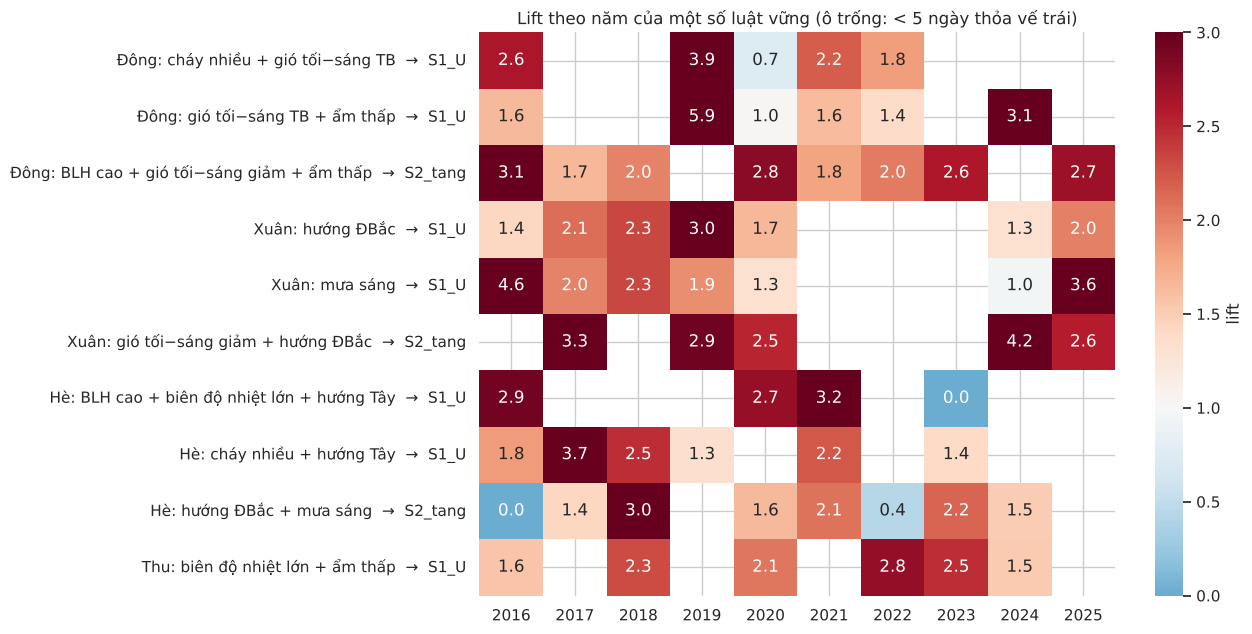

In [16]:
# Lift theo từng năm của các luật vững tiêu biểu (mỗi mùa 1 luật mạnh nhất cho mỗi đích, tối đa 10 luật)
pick = best.groupby("season", observed=True).head(3).head(10)
mat = pd.DataFrame({f"{r['season']}: {r['luật']}": r["lift_by_year"] for _, r in pick.iterrows()}).T.reindex(columns=years)
fig, ax = plt.subplots(figsize=(13, 0.5 * len(mat) + 1.5))
sns.heatmap(mat, annot=True, fmt=".1f", cmap="RdBu_r", center=1, vmin=0, vmax=3, ax=ax, cbar_kws={"label": "lift"})
ax.set_title("Lift theo năm của một số luật vững (ô trống: < 5 ngày thỏa vế trái)"); ax.set_xlabel("")
plt.tight_layout(); plt.savefig(REPORT / "26_robust_by_year.png", bbox_inches="tight"); plt.show()

## 9. So sánh với cách khác: decision tree

Association rules **liệt kê** mọi tổ hợp đi kèm, nhưng không cho biết tổ hợp nào "tách" kiểu ngày tốt nhất và các luật chồng chéo nhau. Một lựa chọn khác là **decision tree** (cây quyết định, mô hình **ML** có giám sát): chia dữ liệu tuần tự theo điều kiện cho nhóm thuần nhất nhất. Mỗi lá của cây cũng là một luật `điều kiện → lớp`, nhưng các luật **không chồng nhau** và được chọn tham lam.

| | Association rules | Decision tree | So sánh tỷ lệ (notebook 04) |
|---|---|---|---|
| Đầu ra | mọi tổ hợp đủ phổ biến và mạnh | một cây, luật không chồng nhau | trung bình/tỷ lệ từng biến theo cụm |
| Tương tác giữa điều kiện | có (đến độ dài max_len) | có (theo độ sâu) | không |
| Rủi ro | bùng nổ số luật, luật dư thừa | không ổn định khi dữ liệu đổi, bỏ sót luật song song | bỏ qua tổ hợp |
| Đánh giá | support/confidence/lift | độ chính xác kiểm định chéo | kiểm định từng biến |

Ở đây dùng cây nông (`max_depth = 3`, mỗi lá ≥ 40 ngày) trên **cùng biến** nhưng ở dạng liên tục đã khử mùa (thứ hạng trong tháng), và đo bằng **balanced accuracy** kiểm định chéo 5 lớp (*5-fold cross-validation*) so với đoán ngẫu nhiên theo tỷ lệ lớp. Hai bài toán: (a) mức "cao" trong mùa Đông, (b) hình dạng trên toàn bộ dữ liệu.

In [17]:
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.dummy import DummyClassifier

F = pd.DataFrame(index=d.index)
for col, name in [("ws_mean", "gió_rank"), ("ws_eve_minus_am", "gió_tối−sáng_rank"), ("blh_mean", "BLH_rank"),
                  ("t_range", "biên_độ_nhiệt_rank"), ("rh_mean", "ẩm_rank")]:
    F[name] = d.groupby("month")[col].rank(pct=True)
F["BLH_rank"] = F["BLH_rank"].fillna(0.5)          # 178 ngày thiếu BLH -> trung vị (cây không nhận NaN trong mọi phiên bản)
F["mưa_mm"] = d["precip_sum"]; F["mưa_sáng_mm"] = d["rain_0_12"]; F["mưa_tối_mm"] = d["rain_12_24"]
F["cháy_ĐBSH"] = d["viirs_n_rrd"]
F["hướng_ĐBắc"] = X["hướng ĐBắc"].astype(int); F["hướng_ĐNam"] = X["hướng ĐNam"].astype(int)
F["Tết"] = d["is_tet_holiday"].astype(int); F["giãn_cách"] = d["lockdown"].astype(int); F["cuối_tuần"] = d["is_weekend"].astype(int)
cv = StratifiedKFold(5, shuffle=True, random_state=0)

def fit_tree(Fx, y, title):
    tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=40, class_weight="balanced", random_state=0)
    sc = cross_val_score(tree, Fx, y, cv=cv, scoring="balanced_accuracy")
    sc0 = cross_val_score(DummyClassifier(strategy="stratified", random_state=0), Fx, y, cv=cv, scoring="balanced_accuracy")
    tree.fit(Fx, y)
    print(f"--- {title}: balanced accuracy CV = {sc.mean():.2f} ± {sc.std():.2f} (ngẫu nhiên: {sc0.mean():.2f})")
    print(export_text(tree, feature_names=list(Fx.columns), decimals=2, show_weights=False))
    imp = pd.Series(tree.feature_importances_, Fx.columns).sort_values(ascending=False)
    print("độ quan trọng:", imp[imp > 0].round(2).to_dict(), "\n")
    return tree

m_dong = (d["season"] == "Đông").values
tree_a = fit_tree(F[m_dong], (d.loc[m_dong, "level_tier"] == "cao").map({True: "cao", False: "không cao"}), "(a) mức cao, mùa Đông")
tree_b = fit_tree(F, d["shape_code"], "(b) hình dạng, toàn bộ")

--- (a) mức cao, mùa Đông: balanced accuracy CV = 0.79 ± 0.04 (ngẫu nhiên: 0.48)
|--- gió_rank <= 0.67
|   |--- mưa_sáng_mm <= 0.05
|   |   |--- biên_độ_nhiệt_rank <= 0.31
|   |   |   |--- class: cao
|   |   |--- biên_độ_nhiệt_rank >  0.31
|   |   |   |--- class: cao
|   |--- mưa_sáng_mm >  0.05
|   |   |--- gió_rank <= 0.27
|   |   |   |--- class: cao
|   |   |--- gió_rank >  0.27
|   |   |   |--- class: không cao
|--- gió_rank >  0.67
|   |--- ẩm_rank <= 0.25
|   |   |--- class: không cao
|   |--- ẩm_rank >  0.25
|   |   |--- gió_tối−sáng_rank <= 0.61
|   |   |   |--- class: không cao
|   |   |--- gió_tối−sáng_rank >  0.61
|   |   |   |--- class: không cao

độ quan trọng: {'gió_rank': 0.7, 'mưa_sáng_mm': 0.19, 'biên_độ_nhiệt_rank': 0.05, 'ẩm_rank': 0.04, 'gió_tối−sáng_rank': 0.02} 

--- (b) hình dạng, toàn bộ: balanced accuracy CV = 0.41 ± 0.01 (ngẫu nhiên: 0.24)
|--- hướng_ĐNam <= 0.50
|   |--- biên_độ_nhiệt_rank <= 0.54
|   |   |--- gió_tối−sáng_rank <= 0.52
|   |   |   |--- class:

**Đọc so sánh:**
- Với **mức** (a), cây đạt độ chính xác rõ hơn ngẫu nhiên, và nhánh đầu tiên thường là gió (thứ hạng trong tháng); đây cũng là điều kiện xuất hiện nhiều nhất trong luật về `mức cao` mùa Đông. Hai phương pháp **thống nhất**.
- Với **hình dạng** (b), cây chỉ khá hơn ngẫu nhiên một chút: điều kiện theo ngày chỉ giải thích một phần nhỏ hình dạng (phù hợp với notebook 04: hình dạng là dải liên tục, ranh giới cụm mờ). Association rules vẫn có ích ở đây vì nó không cần "phân loại đúng" mà chỉ cần tìm **nhóm con** nơi một hình dạng phổ biến hơn hẳn, ví dụ vài chục ngày có lift 2.
- Bài học: lift cao **không có nghĩa** là dự đoán tốt; một luật có thể đúng cho 3% số ngày và chẳng nói gì về 97% còn lại.

## 10. Lưu kết quả

In [18]:
def to_csv(ru, path, cols):
    r = ru.copy()
    for c in ["antecedents", "consequents"]:
        if c in r: r[c] = r[c].apply(lambda s: " + ".join(sorted(s)))
    r[[c for c in cols if c in r]].to_csv(path, index=False)

to_csv(rules_all, OUT / "rules_global.csv", ["luật", "antecedents", "target", "n_days", "support", "confidence", "base", "lift", "leverage", "conviction", "p", "q"])
to_csv(rules_season, OUT / "rules_by_season.csv", ["season", "luật", "antecedents", "target", "n_days", "support", "confidence", "base", "lift",
                                                    "leverage", "q", "n_years", "share_years_lift>1", "min_lift_year", "median_lift_year", "lift_2021_25", "vững"])
best[SHOW2].round(3).to_csv(REPORT / "27_robust_rules_top.csv", index=False)
print("đã lưu:", OUT / "rules_global.csv", OUT / "rules_by_season.csv", REPORT / "27_robust_rules_top.csv")

đã lưu: data/rules_global.csv data/rules_by_season.csv reports/27_robust_rules_top.csv


## 11. Tóm tắt, giới hạn, quyết định

**Phương pháp (mining):** mỗi ngày là một transaction gồm các điều kiện đã rời rạc hóa (thời tiết theo tercile trong cùng tháng; mưa ≥ 1 mm; 3 cung hướng gió; cháy nhiều ≥ P75 của tháng; Tết, giãn cách, cuối tuần) và hai item đích (hình dạng, bậc mức). FP-Growth (`max_len = 4`), chỉ giữ luật `điều kiện → kiểu ngày`, lift ≥ 1,3, luật có ích (+0,05 confidence so với mọi luật con), Fisher từng item + Benjamini–Hochberg q < 0,05. Cách chính là **khai phá trong từng mùa** (≥ 20 ngày): 301 luật, trong đó 257 đạt tiêu chí vững theo năm và holdout.

**Kết quả chính (đều là mối liên hệ, trong cùng mùa):**
1. **Mức cao** đi kèm gió yếu hơn thường lệ, biên độ nhiệt lớn, không khí khô (ẩm thấp, không mưa) và lớp biên thấp; mùa Đông thêm hướng Đông Bắc. Rõ nhất ở mùa Hè, nơi ngày cao vốn hiếm (9%): `gió yếu + ẩm thấp → mức cao` có lift ≈ 5. Mùa Đông, `biên độ nhiệt lớn + gió yếu` → 95% là ngày cao (nền 54%). Decision tree cho cùng kết luận: biến đầu tiên là gió (độ quan trọng 0,70), balanced accuracy 0,79.
2. **Mức thấp** đi kèm mưa (đặc biệt mưa buổi sáng) cùng gió mạnh; mùa Đông `mưa + gió tối giảm + hướng Đông Bắc` cho lift ≈ 5 (khoảng thời điểm không khí lạnh tràn về kèm mưa; đây là giả thuyết, cần đối chiếu bản tin thời tiết).
3. **S1_U (cao đêm, thấp chiều)** đi kèm ngày khô, biên độ nhiệt lớn, nhiều điểm cháy (Thu, Đông) và hướng Đông Bắc; mùa Hè lại đi kèm **hướng Tây + lớp biên cao + khô** (lift ≈ 3), phù hợp với những ngày gió Tây khô nóng: ban ngày trộn mạnh làm loãng, ban đêm lớp nghịch nhiệt giữ bụi lại.
4. **S2_tang (tăng dần về tối)** đi kèm gió **giảm** về tối (mọi mùa), không khí khô và hướng Đông Bắc ở Đông–Xuân.
5. **S3_giam (giảm dần trong ngày)** đi kèm gió **tăng** về tối và hướng Đông Nam (Đông, Thu): không khí từ phía biển thổi vào.
6. **S4_phang** đi kèm gió Đông Nam mạnh và ẩm (Đông, Hè), kỳ nghỉ Tết, ngày khô gió mạnh mùa Xuân.
7. Hình dạng khó dự đoán hơn mức nhiều (decision tree: 0,41 so với 0,24 ngẫu nhiên): điều kiện theo ngày chỉ giải thích một phần hình dạng; các luật về hình dạng mô tả những **nhóm nhỏ** (20–90 ngày) nơi một hình dạng phổ biến gấp 2–3 lần, không phải quy tắc cho mọi ngày.

**Đối chứng âm:** `cuối tuần` còn trong 4/353 luật toàn bộ và 1 luật vững mùa Thu. Với FDR 5% trên vài trăm luật, khoảng 15 luật có thể là phát hiện sai, nên đây là mức kỳ vọng. Bài học: **đừng tin một luật đơn lẻ**; tin những mẫu lặp lại ở nhiều luật, nhiều mùa và qua kiểm tra theo năm (gió, độ khô, biên độ nhiệt, hướng gió).

**Độ vững:** luật tìm trên 2016–2020 vẫn có lift > 1 ở 93% (> 1,1 ở 89%) khi đo trên 2021–2025, nhưng độ lớn lift chỉ tương quan vừa (Spearman 0,43) và thường giảm: đọc lift như cận trên.

**Giới hạn:**
- Một trạm (Ba Đình); thời tiết là tái phân tích ERA5 ~25 km; BLH thiếu nửa đầu 2024; điểm cháy chỉ trong Việt Nam và bị mây che.
- Item "thấp/TB/cao" là **tương đối so với cùng tháng**, không phải giá trị tuyệt đối; luật không nói "gió dưới 2 m/s".
- Kết quả phụ thuộc cách rời rạc hóa và các ngưỡng lọc (min_support, lift, q); đổi các ngưỡng này sẽ đổi số luật, nhưng các mẫu lặp lại nói trên ổn định.
- Nhãn hình dạng là cụm mờ (notebook 04); luật về hình dạng thừa hưởng độ không chắc chắn đó.
- Mẫu theo năm lệch (Xuân 2021–2023, Hè 2019/2022 ít ngày), nên nhiều luật chỉ đánh giá được 4–5 năm.
- **Mối liên hệ, không phải nhân quả.** Ví dụ, "gió yếu → mức cao" không loại trừ việc cả hai cùng do một hình thế thời tiết gây ra, và không đo được đóng góp của nguồn thải.

**Quyết định nên ghi vào "Nhật ký quyết định":**
- Rời rạc hóa: biến thời tiết theo tercile **trong cùng tháng** (khử mùa); mưa theo ngưỡng 1 mm (ETCCDI); hướng gió 3 cung (Đông Bắc, Đông Nam, Tây); cháy nhiều = > 0 và ≥ P75 của tháng.
- Khai phá **trong từng mùa** là cách chính; min_support = 20 ngày mỗi mùa (0,02 khi khai phá toàn bộ), max_len = 4.
- Lọc luật: vế phải là một kiểu ngày/mức; lift ≥ 1,3; luật có ích (+0,05); Fisher từng item + BH q < 0,05.
- Tiêu chí vững: lift > 1 ở ≥ 75% số năm (≥ 4 năm, ≥ 5 ngày/năm) và lift > 1,1 trên 2021–2025.

**Bước tiếp theo trong brief:** anomaly detection (notebook 06), tìm những ngày PM2.5 cao hoặc thấp bất thường so với điều kiện thời tiết của chính ngày đó, rồi đối chiếu với tin tức.